<a href="https://colab.research.google.com/github/fiona-crdt/2026_Intro_Python/blob/main/FEEDBACK_FionaCardot_1_8_ex4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# Pre-supplied: download the data file and cache it locally.
# You do not need to understand this cell yet — fetching data is covered in the
# reproducible-data-pipelines bonus subchapter.
import pooch

penguins_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/palmer_penguins.csv",
    known_hash="sha256:f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93",
    fname="palmer_penguins.csv",
    path=pooch.os_cache("mlees"),
)

## Exercise 4: Clustering the penguin data, at length

Exercise 2 clustered the penguins once, on the two bill measurements, and read the result off a
crosstab. This is the long version of the same question, on a different pair of measurements —
bill length against flipper length, beak against wing — and it asks the question Exercise 2 skipped:
how many clusters should there have been?

Nothing here needs a new dataset. The fetch cell from Exercise 2 already put `penguins_path` in
scope; if you are running this notebook from the top, reuse it.

**ℹ️ Where the tools come from**

Everything here comes from this subchapter: the elbow method, `silhouette_score`, `KMeans`, `.inertia_`,
`.fit`, `.predict` and `.labels_`. The figures in Q4 and Q5 follow the pattern of the k-means plots in this subchapter, with one `plt.scatter` call per species.

**Q1) Clean the data. Drop every row with a missing value in one of the four measurements** (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`).

Call the result `penguin_df` and print its shape. Two birds have no measurements at all; `sex` is missing for a few more, and those rows stay.

In [49]:
# Q1: drop the rows with missing measurements
df = pd.read_csv(penguins_path)
penguin_df = df.dropna(subset=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"])
penguin_df.shape

(342, 8)

**Q2) Create an input array `X` from the `bill_length_mm` and `flipper_length_mm` columns.**

Its shape should be `(342, 2)`. Two columns, because the whole exercise is about being able to see
the answer on a flat plot.

In [16]:
# Q2: build X from bill_length_mm and flipper_length_mm
X = np.array(penguin_df[["bill_length_mm", "flipper_length_mm"]])
X.shape

(342, 2)

**Q3) Train k-means over a range of k, and choose k twice — once by the elbow method and once
by silhouette analysis.**

For k from 1 to 9, fit `KMeans` and record `.inertia_`, the sum of squared distances from each point
to its assigned centre. Plot inertia against k.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-penguin-elbow.png" alt="Inertia falling steeply from k equals 1 to 2 and then flattening, forming an elbow" width="450">

<em>The elbow. Inertia always falls as k rises — with one cluster per point it reaches zero — so the
number you want is not the minimum but the bend, past which each extra cluster buys much less.</em>


Then, for k from 2 to 9, fit again and record `silhouette_score(X, labels)`. Plot that against k
too. Unlike inertia, the silhouette score has a genuine maximum.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-penguin-silhouette.png" alt="Silhouette score peaking sharply at k equals 2 and declining unevenly afterwards" width="450">

<em>The silhouette score, which peaks rather than flattens.</em>


In a comment, say which k each method points at, and whether they agree.

# Block containing an error




In [30]:
# Q3: the elbow plot, then the silhouette plot
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouettes = []

for k in range(1, 10):
    km = KMeans(n_clusters=k, random_state=0, n_init=10)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, labels))

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Elbow plot
axes[0].plot(range(1, 10), inertias)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)

# Silhouette plot
axes[1].plot(range(2, 10), silhouettes)
axes[1].set_title("Silhouette Analysis")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True)

plt.tight_layout()
plt.show()


ValueError: Number of labels is 1. Valid values are 2 to n_samples - 1 (inclusive)

# Explanation

The for loop uses k in range (1,10) to caluclate inertias and silhouettes at the same time. When calculating `silhouette_score`, the following error occurs:

```
# ValueError: Number of labels is 1. Valid values are 2 to n_samples - 1 (inclusive)
```
The loop succesfully computed inertias, but failed at computing silhouettes.

The error shows that I misundersood the definition of inertias and silhouettes and the differences between them.

The propblem is that to compute `silhouettes_scores`, k must be k>1, since the silhouette score is an estimation of the distance between observations within a cluster in comparison to other clusters (cohesion). In the fist version of the `for` loop, k=1 doesn't work to compute silhouette score, since it needs at least two clusters to compare them.

To compute inertias, k=1 works since it measures the squared distance between each point and cluster's centroid.





# Problem solving

We saw that k's range is different for both inertias and silhouettes scores.

We need to code two `for` loops, one for each.

`k in range (1,10)` for `inertias` and
`k in range (2,10)` for `silhouettes_scores`



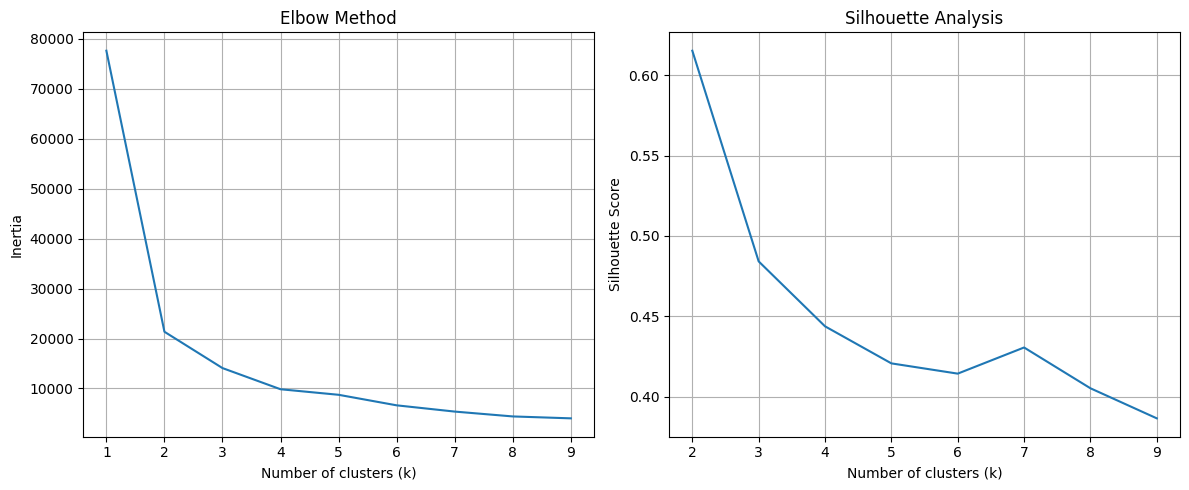

In [25]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
#compute inertias and silhouettes in 2 seperated for loops

# 1: Elbow method
# Computing inertias with k in range (1,10)
inertias = []

for k in range(1, 10):
    km = KMeans(n_clusters=k, random_state=0, n_init=10)
    km.fit(X)
    inertias.append(km.inertia_)

# 2: Silhouette analysis
# Computing silh. scores with k in range (2,10)
silhouettes = []

for k in range(2, 10):
    km = KMeans(n_clusters=k)
    labels = km.fit_predict(X)
    silhouettes.append(silhouette_score(X, labels))

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

  # Elbow method
axes[0].plot(range(1, 10), inertias)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)

#Silhouette analysis
axes[1].plot(range(2, 10), silhouettes)
axes[1].set_title("Silhouette Analysis")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True)

plt.tight_layout()
plt.show()

here both methods suggest to use k=2 (confusing because there is 3 scpcies)

**Q4) Cluster with k = 3 and compare the result against the true species.**

Fit `KMeans(n_clusters=3)`, predict the labels, and store them in `penguin_df` as a `cluster`
column. Then draw one scatter of bill length against flipper length in which the *marker shape*
carries the true species and the *colour* carries the predicted cluster — three
`plt.scatter` calls, one per species, each coloured by `c=subset["cluster"]`.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-penguin-kmeans-3.png" alt="Bill length against flipper length, markers by species and colours by predicted cluster, with Gentoo cleanly separated and Adelie and Chinstrap partly mixed" width="500">

<em>The figure to replicate. Where a marker shape and its colour agree everywhere, k-means found that
species; where one shape carries two colours, it did not.</em>


Hints: pass `cmap="cividis"` and fix the colour range with `vmin=0, vmax=2` on all three calls, or
the three subsets will each be scaled separately and the colours will not mean the same thing.
Use `s=` to vary the marker size and `label=` for the legend.

In a comment: which species does k-means recover, and which two does it confuse?

/tmp/ipykernel_3901/3090859712.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  penguin_df["cluster"] = km.fit_predict(X)


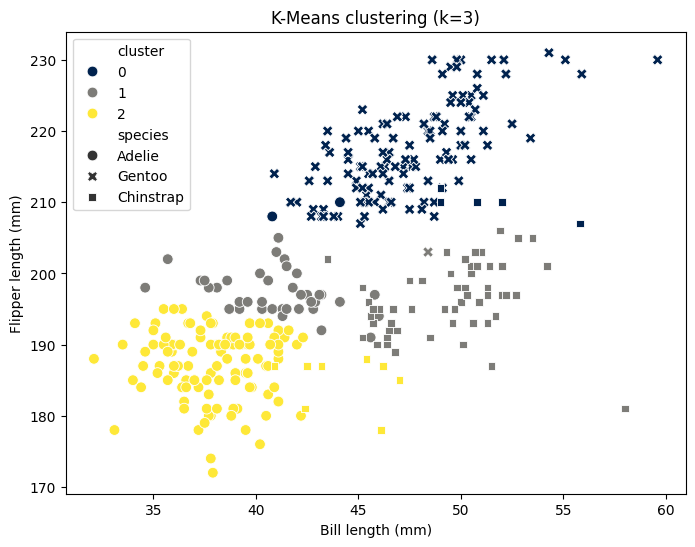

In [50]:
# Q4: k = 3, then the scatter coloured by cluster and shaped by species

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# Train KMeans
km = KMeans(n_clusters=3, random_state=0, n_init=10)
penguin_df["cluster"] = km.fit_predict(X)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=penguin_df,
    x="bill_length_mm",
    y="flipper_length_mm",
    hue="cluster",
    style="species",
    palette="cividis",
    hue_norm=(0, 2),
    s=60
)
plt.xlabel("Bill length (mm)")
plt.ylabel("Flipper length (mm)")
plt.title("K-Means clustering (k=3)")
plt.legend()
plt.show()

**Q5) Now cluster with k = 2 and draw the same figure.**

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-penguin-kmeans-2.png" alt="The same scatter with only two cluster colours, one of them spanning two species" width="500">

<em>The same plot with k = 2, the value the silhouette score preferred.</em>


The silhouette score preferred k = 2; the data has three species. In a comment, say what that
disagreement means. It is not a bug in either method.

/tmp/ipykernel_3901/2625875826.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  penguin_df["cluster"] = km.fit_predict(X)


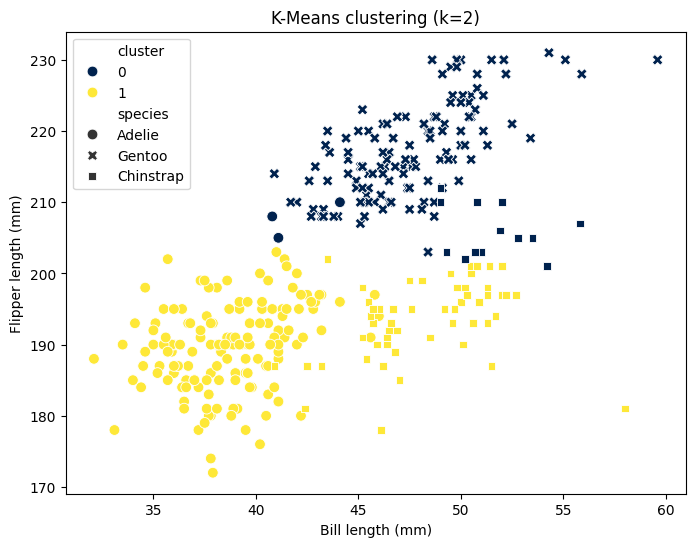

In [53]:
# Q5: k = 2, same figure

km = KMeans(n_clusters=2, random_state=0, n_init=10)
penguin_df["cluster"] = km.fit_predict(X)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=penguin_df,
    x="bill_length_mm",
    y="flipper_length_mm",
    hue="cluster",
    style="species",
    palette="cividis",
    hue_norm=(0, 1),
    s=60
)

plt.xlabel("Bill length (mm)")
plt.ylabel("Flipper length (mm)")
plt.title("K-Means clustering (k=2)")
plt.legend()
plt.show()

It means that flipper length and bill length are not ood indicators of the species (not sufficient to cluster them)